# MLP Project Milestone 2 — Data Preprocessing
## Workstation Rental `price_tier` project

**How to use:** Open this notebook in your Kaggle notebook environment (or Jupyter with the CSV files available). Run cells from top to bottom. Use your real outputs to write the report—do not guess numbers.

Target: `price_tier` (multiclass classification, classes 1–4). We will fit preprocessing only on training data to avoid leakage.

## 0. Load the competition data

In [1]:
print(1)

1


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_path = 'data/train.csv'
test_path = "data/test.csv"
sample_path = "data/sample_submission.csv"


train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
sample = pd.read_csv(sample_path) if sample_path and os.path.exists(sample_path) else None

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Target present:", "price_tier" in train.columns)
display(train.head())
display(train.dtypes.to_frame("dtype"))


Train shape: (279746, 60)
Test shape: (114538, 59)
Target present: True


,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2
3,3,Spesspe,2.0,1.0,2.0,1.0,unverified_operator,t,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.60,MTR-09,4
4,4,Gosho,2.0,7.0,2.0,4.0,unverified_operator,t,1.0,t,...,9.42,9.74,licensed,1,1,0,0,4.64,MTR-08,3


,dtype
space_id,int64
operator_ref,str
operator_platform_age_years,float64
operator_platform_age_months,float64
operator_active_years,float64
operator_active_months,float64
operator_class,str
operator_certified,str
operator_portfolio_size,float64
operator_has_avatar,str


## 1. Dataset profile — evidence for Q1

In [2]:
print("Duplicate rows:", train.duplicated().sum())
print("\nMissing values (top 30):")
display(train.isna().sum().sort_values(ascending=False).head(30).to_frame("missing_count"))
print("\nMissing percentage (top 30):")
display((100 * train.isna().mean()).sort_values(ascending=False).head(30).round(2).to_frame("missing_percent"))
print("\nNumeric summary:")
display(train.describe().T)
print("\nTarget counts:")
display(train["price_tier"].value_counts(dropna=False).sort_index().to_frame("count"))
print("\nTarget proportions (%):")
display((100 * train["price_tier"].value_counts(normalize=True).sort_index()).round(2).to_frame("percent"))


Duplicate rows: 0

Missing values (top 30):


,missing_count
borough,214451
score_value,54246
score_access,54245
score_onboarding,54243
score_accuracy,54242
score_support,54241
first_review_date,54240
last_review_date,54240
score_condition,54240
reviews_per_month,54240



Missing percentage (top 30):


,missing_percent
borough,76.66
score_value,19.39
score_access,19.39
score_onboarding,19.39
score_accuracy,19.39
score_support,19.39
first_review_date,19.39
last_review_date,19.39
score_condition,19.39
reviews_per_month,19.39



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
space_id,279746.0,139872.500000,8.075586e+04,0.0000,69936.2500,139872.5000,209808.7500,2.797450e+05
operator_platform_age_years,279142.0,6.794735,4.187652e+00,0.0000,3.0000,7.0000,10.0000,1.700000e+01
operator_platform_age_months,279142.0,5.453275,3.489590e+00,0.0000,2.0000,5.0000,9.0000,1.100000e+01
operator_active_years,279140.0,5.083295,4.040029e+00,0.0000,2.0000,4.0000,8.0000,1.500000e+01
operator_active_months,279140.0,5.298635,3.480848e+00,0.0000,2.0000,5.0000,8.0000,1.100000e+01
operator_portfolio_size,279142.0,49.472043,3.327522e+02,0.0000,1.0000,4.0000,19.0000,5.978000e+03
geo_lat,279746.0,77.766908,3.751376e+01,-4.8180,68.0415,94.6230,100.9410,1.117680e+02
geo_lon,279746.0,-35.144810,5.717006e+01,-123.7498,-76.5598,-31.1326,-21.2656,8.704520e+01
max_seats,279746.0,3.627312,2.277564e+00,1.0000,2.0000,3.0000,4.0000,1.600000e+01
utility_rooms,249847.0,1.358645,8.063074e-01,0.5000,1.0000,1.0000,1.5000,5.000000e+01



Target counts:


,count
price_tier,
1,66889
2,81530
3,60839
4,70488



Target proportions (%):


,percent
price_tier,
1,23.91
2,29.14
3,21.75
4,25.20


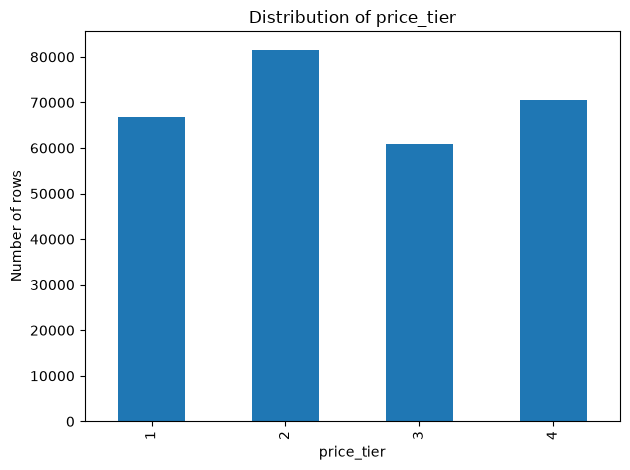

In [3]:
# Visualize target balance
ax = train["price_tier"].value_counts().sort_index().plot(kind="bar")
ax.set_title("Distribution of price_tier")
ax.set_xlabel("price_tier")
ax.set_ylabel("Number of rows")
plt.tight_layout()
plt.show()


## 2. Inspect possible duplicates, invalid values and categories — Q2

In [4]:
# Exact duplicate rows and duplicate identifiers (if any)
print("Exact duplicate rows:", train.duplicated().sum())
for col in ["ID", "space_id"]:
    if col in train.columns:
        print(f"Duplicate values in {col}:", train[col].duplicated().sum())

# Categorical/object columns and their number of unique values
obj_cols = train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
cat_summary = pd.DataFrame({
    "dtype": train[obj_cols].dtypes.astype(str),
    "n_unique": train[obj_cols].nunique(dropna=False),
    "missing": train[obj_cols].isna().sum()
}).sort_values("n_unique")
display(cat_summary)
for col in obj_cols:
    print("\n", col, "— most common values")
    display(train[col].value_counts(dropna=False).head(12).to_frame("count"))


Exact duplicate rows: 0
Duplicate values in space_id: 0


C:\Users\acer\AppData\Local\Temp\ipykernel_9436\1510583125.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


,dtype,n_unique,missing
operator_class,str,3,0
operator_certified,str,3,604
operator_has_avatar,str,3,604
operator_id_verified,str,3,604
bookable,str,3,97
access_type,str,4,0
compliance_status,str,4,0
metro,str,16,0
borough,str,56,214451
space_class,str,131,0



 operator_ref — most common values


,count
operator_ref,
Bessstu,1467
Zianovath,1160
Nalsto,1088
Dessselra,1030
Stianianlo,949
Klynfova,946
Sinnovara,801
Zelten,773
Snyniv,750



 operator_class — most common values


... (27 outputs left out)


 compliance_status — most common values


,count
compliance_status,
unlicensed,154603
licensed,96742
exempt,21194
in_review,7207



 metro — most common values


,count
metro,
MTR-09,35746
MTR-11,28781
MTR-10,28544
MTR-01,21408
MTR-02,20903
MTR-07,18291
MTR-16,18277
MTR-12,18234
MTR-13,13239


## 3. Missing-value analysis — Q3

In [ ]:
missing = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing_count": train.isna().sum(),
    "missing_percent": (100 * train.isna().mean()).round(2),
    "n_unique": train.nunique(dropna=False)
})
display(missing[missing["missing_count"] > 0].sort_values("missing_percent", ascending=False))


## 4. Outlier analysis — Q4

In [ ]:
num_cols = train.select_dtypes(include=np.number).columns.drop("price_tier", errors="ignore")
outlier_rows = []
for col in num_cols:
    s = train[col].dropna()
    if len(s) == 0:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "column": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": low, "upper_bound": high,
        "outlier_count": int(((s < low) | (s > high)).sum()),
        "outlier_percent": round(100 * ((s < low) | (s > high)).mean(), 2)
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_percent", ascending=False)
display(outlier_summary)


## 5. Scaling analysis — Q5

Do not scale the entire dataset before splitting. In Q9, use a pipeline so the scaler learns parameters from training data only. Usually scale continuous numeric predictors for distance/gradient-based models; do not automatically scale IDs or the target.

In [ ]:
# Review numeric columns and ranges to decide what is a real feature vs identifier
numeric_profile = train.select_dtypes(include=np.number).describe().T
numeric_profile["n_unique"] = train.select_dtypes(include=np.number).nunique()
display(numeric_profile.sort_values("std", ascending=False))


## 6. Categorical encoding analysis — Q6

In [ ]:
# List categories with high cardinality; these may need special handling
cat_cols = train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
cat_profile = pd.DataFrame({
    "n_unique": train[cat_cols].nunique(dropna=False),
    "missing": train[cat_cols].isna().sum()
}).sort_values("n_unique", ascending=False)
display(cat_profile)


## 7. Other non-numeric columns — Q7

In [ ]:
# Look for date-like column names and inspect example values
date_like = [c for c in train.columns if any(k in c.lower() for k in ["date", "time", "timestamp"])]
print("Possible date/time columns:", date_like)
for col in date_like:
    print("\n", col)
    display(train[col].head(10).to_frame())


## 8. Target variable and class balance — Q8

In [ ]:
target_counts = train["price_tier"].value_counts(dropna=False).sort_index()
target_table = pd.DataFrame({
    "count": target_counts,
    "percent": (100 * target_counts / len(train)).round(2)
})
display(target_table)
print("Target missing values:", train["price_tier"].isna().sum())
print("Target data type:", train["price_tier"].dtype)


## 9. Preprocessing pipeline — Q9 (starter template)

This is a safe general template, but inspect the dataset first and adjust columns. It separates numeric and categorical columns, imputes missing values, scales numeric features, and one-hot encodes categorical features. Do not include IDs or `price_tier` in the features without a reason. High-cardinality columns may need a different encoding strategy.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = train.drop(columns=["price_tier"])
y = train["price_tier"]

# Remove obvious identifier columns only after confirming their meaning.
id_candidates = [c for c in X.columns if c.lower() in ["id", "playerid", "row_id"]]
X = X.drop(columns=id_candidates, errors="ignore")

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_valid_ready = preprocessor.transform(X_valid)

print("Before:", X_train.shape, X_valid.shape)
print("After:", X_train_ready.shape, X_valid_ready.shape)
print("Same transformed feature count:", X_train_ready.shape[1] == X_valid_ready.shape[1])


## 10. Baseline comparison — Q10

Use the same train/validation split and same model for both comparisons. A simple, defensible baseline for multiclass classification is Logistic Regression. The minimally processed comparison still needs missing-value handling and categorical encoding to be model-compatible; compare it against the full pipeline. For a large dataset, start with a manageable sample if runtime is too high, and state that limitation in the report.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.dummy import DummyClassifier

# Baseline: majority-class prediction
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_ready, y_train)
dummy_pred = dummy.predict(X_valid_ready)
print("Dummy accuracy:", round(accuracy_score(y_valid, dummy_pred), 4))
print("Dummy macro-F1:", round(f1_score(y_valid, dummy_pred, average="macro"), 4))

# Logistic Regression on the full preprocessing pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)
pred = model.predict(X_valid)
print("Logistic Regression accuracy:", round(accuracy_score(y_valid, pred), 4))
print("Logistic Regression macro-F1:", round(f1_score(y_valid, pred, average="macro"), 4))
print(classification_report(y_valid, pred))


## Before writing the report

1. Run the notebook from the top.
2. Save the output of the dataset profile and target counts.
3. Inspect the highest-missing columns, categorical cardinality, and outlier table.
4. Do not claim that a preprocessing step improved performance until you have measured it.
5. Paste your own code and summarize your actual outputs in the milestone document.

**Important:** This is a starter notebook, not a finished analysis. Some columns—especially identifiers, date fields, and high-cardinality categories—need decisions based on their actual meaning and your outputs.